# Reshaping data: wide and long formats

A **wide-format** table stores repeated categories in separate columns. A **long-format** table stores those category labels in one column and their observations in another. Neither representation is universally better: choose the one that preserves the meaning of each row and works well with the next operation.

This notebook shows how to:

- reshape wide data to long data with `melt()`;
- reshape long data to wide data with `pivot()`; and
- verify whether a round trip really preserves the original observations.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## Wide-format data

The synthetic weather data contain one row per date and one temperature column per station. Both measurement columns therefore represent the same physical quantity, in degrees Celsius.

In [2]:
wide_data = pd.read_csv("data/weather.csv", parse_dates=["date"])
wide_data

,date,north,south
0,2026-01-01,3,6
1,2026-01-02,5,7
2,2026-01-03,4,7
3,2026-01-04,7,9
4,2026-01-05,8,10
5,2026-01-06,6,8
6,2026-01-07,4,6


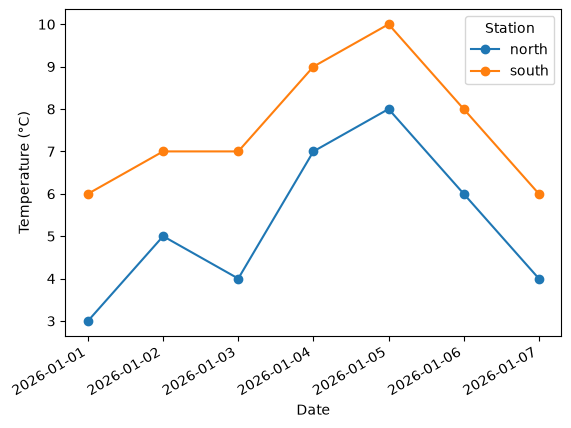

In [3]:
fig, ax = plt.subplots()
for station in wide_data.columns.drop("date"):
    ax.plot(wide_data["date"], wide_data[station], marker="o", label=station)
ax.set(xlabel="Date", ylabel="Temperature (°C)")
ax.legend(title="Station")
fig.autofmt_xdate()
plt.show()

## From wide to long with `melt()`

The `date` column identifies an observation and remains unchanged. The station names move from the column axis into a `station` column, while the temperatures move into a `temperature_c` column.

In [4]:
long_data = wide_data.melt(
    id_vars="date",
    var_name="station",
    value_name="temperature_c",
)
long_data

,date,station,temperature_c
0,2026-01-01,north,3
1,2026-01-02,north,5
2,2026-01-03,north,4
3,2026-01-04,north,7
4,2026-01-05,north,8
5,2026-01-06,north,6
6,2026-01-07,north,4
7,2026-01-01,south,6
8,2026-01-02,south,7
9,2026-01-03,south,7


Long format is convenient when a plotting function maps a category such as `station` to colour. The y-axis still represents one variable with one unit.

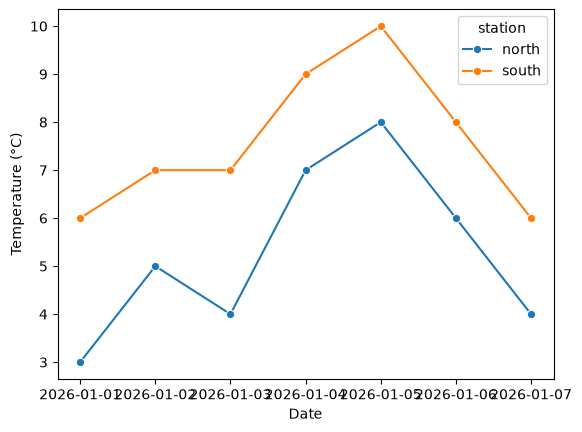

In [5]:
ax = sns.lineplot(
    data=long_data,
    x="date",
    y="temperature_c",
    hue="station",
    marker="o",
)
ax.set(xlabel="Date", ylabel="Temperature (°C)")
plt.show()

## From long to wide with `pivot()`

The inverse reshape uses the dates as row labels, the station names as columns, and the temperatures as cell values. `reset_index()` restores `date` as an ordinary column. `rename_axis()` removes the descriptive name attached to the column axis.

In [6]:
restored_wide_data = (
    long_data.pivot(
        index="date",
        columns="station",
        values="temperature_c",
    )
    .reset_index()
    .rename_axis(columns=None)
    .reindex(columns=wide_data.columns)
)
restored_wide_data

,date,north,south
0,2026-01-01,3,6
1,2026-01-02,5,7
2,2026-01-03,4,7
3,2026-01-04,7,9
4,2026-01-05,8,10
5,2026-01-06,6,8
6,2026-01-07,4,6


A visual comparison is not enough to establish a lossless round trip. This assertion checks values, data types, row labels, column labels, and column order.

In [7]:
pd.testing.assert_frame_equal(restored_wide_data, wide_data)
"The round trip preserved the dataframe exactly."

'The round trip preserved the dataframe exactly.'

## Choosing a representation

Wide format is often convenient for matrices, spreadsheets, and algorithms that expect one feature per column. Long format is often convenient for grouped operations and visualizations, and adding another category usually adds rows rather than columns.

The choice must also respect semantics. Do not put measurements with incompatible units into one value column merely to satisfy a plotting API. If measurement types differ, keep separate value columns or record enough metadata to interpret every value.

## Optional: multiple values and missing combinations

The patient data contain two measured variables, `temperature` and `dose`. Pivoting both creates two column levels: the measured variable and the patient identifier. This is useful, but it also exposes a round-trip risk that the simpler example does not have.

In [8]:
patient_data = pd.read_excel(
    "data/patient_experiment.xlsx",
    dtype={"dose": "float32", "temperature": "float32"},
)
patient_data.head()

,patient,dose,date,temperature
0,1,0.0,2012-10-02 10:00:00,38.299999
1,1,2.0,2012-10-02 11:00:00,38.500000
2,1,2.0,2012-10-02 12:00:00,38.099998
3,1,2.0,2012-10-02 13:00:00,37.299999
4,1,0.0,2012-10-02 14:00:00,37.500000


In [9]:
patient_wide = patient_data.pivot(
    index="date",
    columns="patient",
    values=["temperature", "dose"],
)
patient_wide.head()

temperature                                              \
patient                       1          2          3          4          5   
date                                                                          
2012-10-02 10:00:00   38.299999  39.299999  37.900002  38.099998  37.900002   
2012-10-02 11:00:00   38.500000  39.400002  39.500000  37.200001  39.500000   
2012-10-02 12:00:00   38.099998  38.099998  38.299999  36.099998  38.299999   
2012-10-02 13:00:00   37.299999  37.299999        NaN  35.900002  38.500000   
2012-10-02 14:00:00   37.500000  36.799999  37.700001  36.299999  39.400002   

                                                                dose       \
patient                      6          7          8          9    1    2   
date                                                                        
2012-10-02 10:00:00  37.500000  39.500000  37.799999  38.299999  0.0  0.0   
2012-10-02 11:00:00  38.099998  40.700001  37.900002  39.500000  2.0  5.0   
2012-10-02 12:00:00  37.900002  39.799999  37.400002  40.200001  2.0  5.0   
2012-10-02 13:00:00  37.700001  40.200001  37.599998  39.099998  2.0  5.0   
2012-10-02 14:00:00  37.200001  38.299999  37.299999  37.900002  0.0  0.0   

                                                          
patient                3    4    5    6     7    8     9  
date                                                      
2012-10-02 10:00:00  0.0  0.0  0.0  0.0   0.0  0.0   0.0  
2012-10-02 11:00:00  2.0  5.0  3.0  2.0  10.0  0.0  10.0  
2012-10-02 12:00:00  5.0  5.0  7.0  3.0   5.0  0.0  12.0  
2012-10-02 13:00:00  2.0  0.0  5.0  2.0   8.0  0.0   4.0  
2012-10-02 14:00:00  2.0  NaN  9.0  1.0   3.0  0.0   4.0

Stacking the patient level returns to a long representation. However, the wide table represents every observed date combined with every observed patient. The original table need not contain every one of those combinations.

In [10]:
patient_long_again = (
    patient_wide.stack("patient")
    .reset_index()
    .rename_axis(columns=None)
)
pd.Series(
    {
        "source rows": len(patient_data),
        "round-trip rows": len(patient_long_again),
    }
)

source rows        62
round-trip rows    63
dtype: int64

Comparing the identifying columns reveals the added date-patient combination. Both measurements are missing because that observation was absent from the source table.

In [11]:
key_columns = ["date", "patient"]
added_rows = (
    patient_long_again.merge(
        patient_data[key_columns],
        on=key_columns,
        how="left",
        indicator=True,
    )
    .query("_merge == 'left_only'")
    .drop(columns="_merge")
)
assert len(added_rows) == 1
added_rows

,date,patient,temperature,dose
59,2012-10-02 16:00:00,6,NaN,NaN


Dropping every row whose measurements are all missing is not a generally safe repair: a real source row may legitimately contain only missing measurements. If row presence matters, preserve an explicit observation indicator or compare the identifying keys before and after reshaping.

## Summary

Use `melt()` when category labels stored in several columns should become rows. Use `pivot()` when values stored in rows should become columns and each index-column combination is unique. After any purported round trip, verify the schema, identifying keys, missing-value pattern, and values rather than relying on appearance alone.